In [1]:
import os
import utils
import torch
import pickle
import numpy as np
import matplotlib.pyplot as plt

from torch import nn
from torch.utils.data import DataLoader, Subset
from sklearn.manifold import TSNE

# PARAMETRI

In [2]:
EPOCHS = 10
BATCH_SIZE = 64
LEARNING_RATE = 0.001
DEVICE = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.device('cpu')

print(f"DEVICE: {DEVICE}")

DEVICE: cuda


TRAIN SET shape: (50000, 32, 32, 3)
TEST SET shape:  (10000, 32, 32, 3)


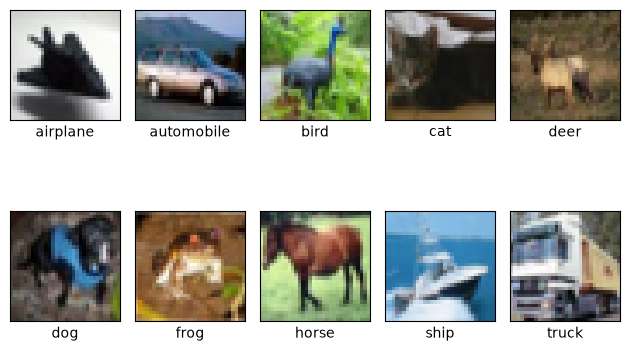

In [3]:
from datasets.datasets import load_CIFAR10
train_dataset, test_dataset, train_loader, test_loader = load_CIFAR10(batch_size=BATCH_SIZE, verbose=False)

print(f"TRAIN SET shape: {train_dataset.data.shape}")
print(f"TEST SET shape:  {test_dataset.data.shape}")

for c in range(len(train_dataset.classes)):
    idx = train_dataset.targets.index(c)   # primo esempio della classe c
    img, label = train_dataset[idx]
    plt.subplot(2, 5, c + 1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(img.permute(1, 2, 0))
    plt.xlabel(train_dataset.classes[label])
plt.tight_layout()
plt.show()

# MODELLO

In [4]:
#Parametri del modello
IN_CHANNELS = 3
FILTERS = 32
LATENT_CHANNELS = 8
KERNEL_SIZE = 3

In [5]:
#Parametri del modello
encoder = nn.Sequential(
    nn.Conv2d(IN_CHANNELS, FILTERS, KERNEL_SIZE, padding='same'), nn.ReLU(),         # (B, C, H, W)      -> (B, 32, H, W)
    nn.MaxPool2d(kernel_size=2),                                                     # (B, 32, H, W)     -> (B, 32, H/2, W/2)
    nn.Conv2d(FILTERS, LATENT_CHANNELS, KERNEL_SIZE, padding='same'), nn.ReLU(),     # (B, 32, H/2, W/2) -> (B, 8, H/2, W/2)
    nn.MaxPool2d(kernel_size=2),                                                     # (B, 8, H/2, W/2)  -> (B, 8, H/4, W/4)
)

decoder = nn.Sequential(
    nn.Upsample(scale_factor=2, mode='nearest'),                                     # (B, 8, H/4, W/4)  -> (B, 8, H/2, W/2)
    nn.ConvTranspose2d(LATENT_CHANNELS, FILTERS, KERNEL_SIZE, padding=1), nn.ReLU(), # (B, 8, H/2, W/2)  -> (B, 32, H/2, W/2)
    nn.Upsample(scale_factor=2, mode='nearest'),                                     # (B, 32, H/2, W/2) -> (B, 32, H, W)
    nn.ConvTranspose2d(FILTERS, IN_CHANNELS, KERNEL_SIZE, padding=1), nn.Sigmoid(),  # (B, 32, H, W)     -> (B, C, H, W)
)

autoencoder = nn.Sequential(encoder, decoder).to(DEVICE)

# class ConvAutoEncoder(nn.Module):
#     def __init__(self, in_channels, filters, latent_channels, kernel_size):
#         super().__init__()
#         self.encoder = nn.Sequential(nn.Conv2d(in_channels, filters, kernel_size, padding='same'), nn.ReLU(),
#                                      nn.MaxPool2d(kernel_size=2),
#                                      nn.Conv2d(filters, latent_channels, kernel_size, padding='same'), nn.ReLU(),
#                                      nn.MaxPool2d(kernel_size=2))
#         self.decoder = nn.Sequential(nn.Upsample(scale_factor=2, mode='nearest'),
#                                      nn.ConvTranspose2d(latent_channels, filters, kernel_size, padding=1), nn.ReLU(),
#                                      nn.Upsample(scale_factor=2, mode='nearest'),
#                                      nn.ConvTranspose2d(filters, in_channels, kernel_size, padding=1), nn.Sigmoid())
#     def forward(self, x):
#         return self.decoder(self.encoder(x))
# autoencoder = ConvAutoEncoder(IN_CHANNELS, FILTERS, LATENT_CHANNELS, KERNEL_SIZE).to(DEVICE)
# encoder = autoencoder.encoder

optimizer = torch.optim.Adam(autoencoder.parameters(), lr=LEARNING_RATE, eps=1e-7)
criterion = nn.MSELoss()

autoencoder

Sequential(
  (0): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 8, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (1): Sequential(
    (0): Upsample(scale_factor=2.0, mode='nearest')
    (1): ConvTranspose2d(8, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): ReLU()
    (3): Upsample(scale_factor=2.0, mode='nearest')
    (4): ConvTranspose2d(32, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): Sigmoid()
  )
)

![Testo alternativo](imgs/upsample_vs_convtranspose_2x2.png)

In [6]:
utils.summary(encoder, train_dataset[0][0].shape)
utils.summary(decoder, (8,8,8))

Layer (type)                Output Shape               Param #
0 (Conv2d)                  (None, 32, 32, 32)             896
1 (ReLU)                    (None, 32, 32, 32)               0
2 (MaxPool2d)               (None, 32, 16, 16)               0
3 (Conv2d)                  (None, 8, 16, 16)            2,312
4 (ReLU)                    (None, 8, 16, 16)                0
5 (MaxPool2d)               (None, 8, 8, 8)                  0
Total params: 3,208
Trainable params: 3,208
Non-trainable params: 0
Layer (type)                Output Shape               Param #
0 (Upsample)                (None, 8, 16, 16)                0
1 (ConvTranspose2d)         (None, 32, 16, 16)           2,336
2 (ReLU)                    (None, 32, 16, 16)               0
3 (Upsample)                (None, 32, 32, 32)               0
4 (ConvTranspose2d)         (None, 3, 32, 32)              867
5 (Sigmoid)                 (None, 3, 32, 32)                0
Total params: 3,203
Trainable params: 3,203
Non-tr

# ADDESTRAMENTO

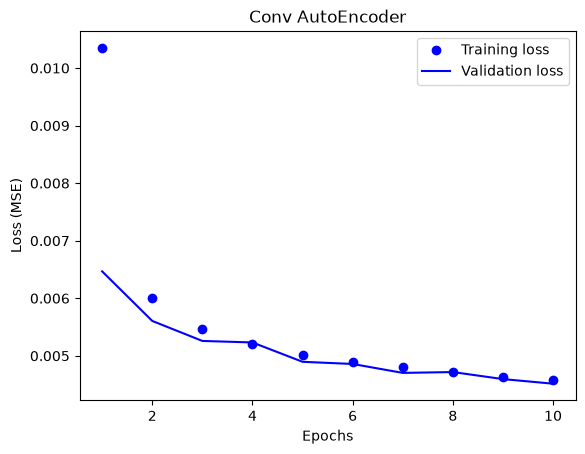

In [7]:
os.makedirs('histories', exist_ok=True)

filename = "conv_ae"
hist_path = f'histories/{filename}.hist'
weights_path = f'histories/{filename}.pt'

if os.path.isfile(hist_path) and os.path.isfile(weights_path):
    with open(hist_path, 'rb') as hist_file:
        history_dict = pickle.load(hist_file)
    autoencoder.load_state_dict(torch.load(weights_path, map_location=DEVICE))
else:
    history_dict = utils.train_autoencoder(autoencoder, optimizer, criterion,
                                     train_loader, test_loader, EPOCHS, DEVICE)
    with open(hist_path, 'wb') as hist_file:
        pickle.dump(history_dict, hist_file)
    torch.save(autoencoder.state_dict(), weights_path)

epochs = range(1, len(history_dict['loss']) + 1)
plt.figure()
plt.plot(epochs, history_dict['loss'], 'bo', label='Training loss')
plt.plot(epochs, history_dict['val_loss'], 'b', label='Validation loss')
plt.title('Conv AutoEncoder')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.legend(loc='upper right')
plt.show()

# VALUTAZIONE

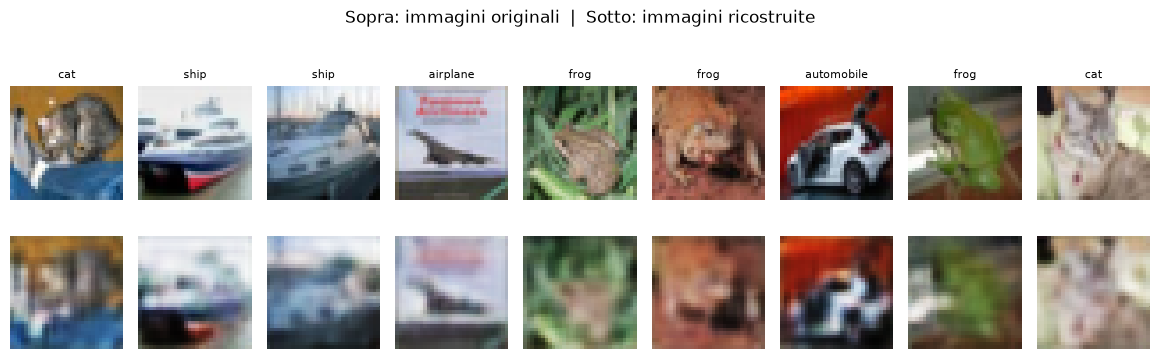

In [8]:
# TEST: ricostruzione di alcune immagini del test set
autoencoder.eval()
x, y = next(iter(test_loader))
with torch.no_grad():
    x_rec = autoencoder(x.to(DEVICE)).cpu()

n_show = 9
plt.figure(figsize=(1.3 * n_show, 4))
for i in range(n_show):
    plt.subplot(2, n_show, i + 1)
    plt.imshow(x[i].permute(1, 2, 0))       # (3, 32, 32) -> (32, 32, 3)
    plt.title(test_dataset.classes[y[i]], fontsize=8)
    plt.axis('off')
    plt.subplot(2, n_show, n_show + i + 1)
    plt.imshow(x_rec[i].permute(1, 2, 0))
    plt.axis('off')
plt.suptitle('Sopra: immagini originali  |  Sotto: immagini ricostruite')
plt.tight_layout()
plt.show()

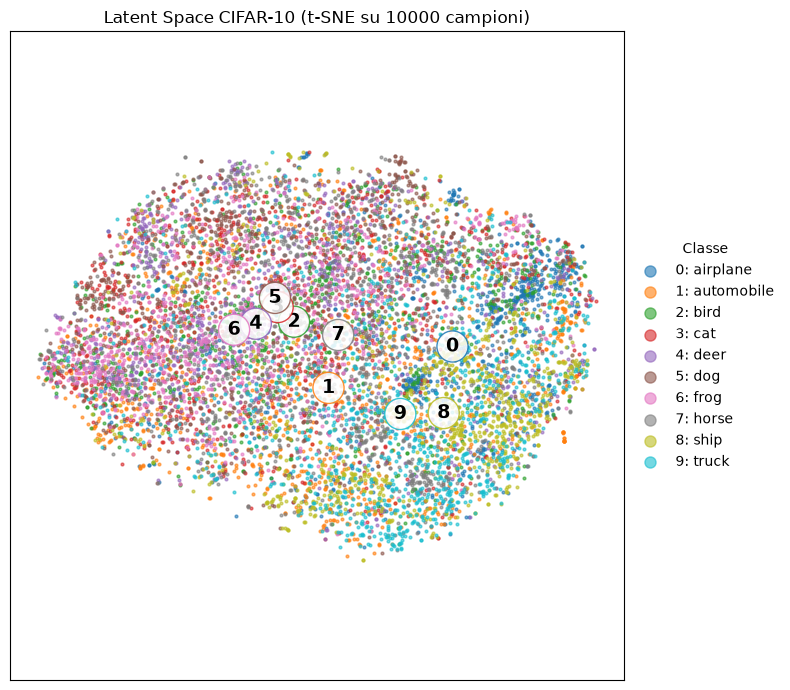

In [9]:
# LATENT SPACE (t-SNE)
n_tsne = 10000
rng = np.random.default_rng(0)
idx = rng.choice(len(train_dataset), size=n_tsne, replace=False)
subset_loader = DataLoader(Subset(train_dataset, idx), batch_size=1024, shuffle=False)

encoder.eval()
codes, labels = [], []
with torch.no_grad():
    for x, y in subset_loader:
        codes.append(encoder(x.to(DEVICE)).flatten(1).cpu())   # codici latenti 32x16x16 -> 8192 dimensioni
        labels.append(y)
proj = torch.cat(codes).numpy()
labels = torch.cat(labels).numpy()

tsne = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=0)
emb = tsne.fit_transform(proj)

class_names = train_dataset.classes   # ['airplane', 'automobile', 'bird', 'cat', ...]

plt.figure(figsize=(8, 7))
cmap = plt.get_cmap('tab10')
for d, name in enumerate(class_names):
    m = labels == d
    plt.scatter(emb[m, 0], emb[m, 1], s=4, alpha=0.6, color=cmap(d), label=f'{d}: {name}')
    cx, cy = np.median(emb[m], axis=0)
    plt.text(cx, cy, str(d), fontsize=14, weight='bold', ha='center', va='center',
             bbox=dict(boxstyle='circle', facecolor='white', edgecolor=cmap(d), alpha=0.85))
plt.legend(title='Classe', markerscale=4, loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
plt.xticks([])
plt.yticks([])
plt.gca().set_aspect('equal', 'datalim')
plt.title(f'Latent Space CIFAR-10 (t-SNE su {n_tsne} campioni)')
plt.tight_layout()
plt.show()